# Analyse — benchmark de compréhension temporelle vidéo (E2)

Groupe **Les Provinciaux**. Ce notebook relit les résultats bruts (`results/*.jsonl`) produits par `python -m tvbench.run`
et en tire les tableaux et figures de la soutenance. Il ne fait **aucun appel payant** : il peut être ré-exécuté hors-ligne.

**Questions de recherche**
1. Quelle exactitude par catégorie (ordre, comptage, causalité, détail fugitif) pour chaque modèle, comparée au hasard ?
2. Les réponses sont-elles stables quand on reformule la question ?
3. Que change la sélection adaptative des frames, en particulier pour les détails fugitifs ?
4. Les erreurs viennent-elles de la **perception** (l'information n'est pas dans les frames) ou de la **compréhension** ?
5. Quel coût et quelle latence ?

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from tvbench.metrics import summarize, wilson, evidence_seen, CATS

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
MODEL_LABEL = {"random": "Hasard", "gemini-flash-lite-or": "Gemini 3.5 Flash-Lite",
               "qwen-27b-or": "Qwen 3.8-27B", "qwen-9b-or": "Qwen 3.5-9B"}
MODEL_ORDER = [m for m in MODEL_LABEL]
COLORS = {"random": "#9e9e9e", "gemini-flash-lite-or": "#1a73e8", "qwen-27b-or": "#7b3fbf", "qwen-9b-or": "#d9822b"}
CAT_LABEL = {"order": "Ordre", "counting": "Comptage", "causality": "Causalité", "fleeting": "Détail fugitif"}

frames = []
for name, corpus in [("synthetic.jsonl", "contrôlé"), ("real.jsonl", "réel")]:
    p = ROOT / "results" / name
    if p.exists():
        d = pd.read_json(p, lines=True); d["corpus"] = corpus; frames.append(d)
df = pd.concat(frames, ignore_index=True)
df = df[df["error"].isna()].copy()
df["seen"] = df.apply(evidence_seen, axis=1)
print(df.groupby(["corpus", "model", "strategy"]).size().unstack())

strategy                       adaptive  uniform
corpus   model                                  
contrôlé gemini-flash-lite-or       240      240
         qwen-27b-or                240      240
         qwen-9b-or                 240      240
         random                     240      240
réel     gemini-flash-lite-or       240      240
         qwen-27b-or                240      240
         qwen-9b-or                 240      240
         random                     240      240


## 1. Vue d'ensemble

In [2]:
tables = {c: summarize(g) for c, g in df.groupby("corpus")}
for c, t in tables.items():
    print(f"=== corpus {c}")
    cols = ["model", "strategy", "n", "acc", "acc_ci"] + [f"acc_{k}" for k in CATS] + ["consistency", "robust_acc", "top_letter_share", "eur_per_100q", "lat_p50_s"]
    display(t[cols].round(3))

=== corpus contrôlé


,model,strategy,n,acc,acc_ci,acc_order,acc_counting,acc_causality,acc_fleeting,consistency,robust_acc,top_letter_share,eur_per_100q,lat_p50_s
0,gemini-flash-lite-or,adaptive,240,0.729,"[0.67, 0.78]",0.883,0.350,0.683,1.000,0.662,0.612,0.363,0.121,1.296
1,gemini-flash-lite-or,uniform,240,0.542,"[0.48, 0.60]",0.833,0.250,0.517,0.567,0.562,0.412,0.428,0.121,1.337
2,qwen-27b-or,adaptive,240,0.717,"[0.66, 0.77]",0.750,0.317,0.800,1.000,0.650,0.600,0.300,0.016,1.004
3,qwen-27b-or,uniform,240,0.642,"[0.58, 0.70]",0.817,0.367,0.800,0.583,0.512,0.462,0.321,0.016,1.011
4,qwen-9b-or,adaptive,240,0.729,"[0.67, 0.78]",0.850,0.300,0.767,1.000,0.788,0.675,0.338,0.025,1.074
5,qwen-9b-or,uniform,240,0.621,"[0.56, 0.68]",0.800,0.183,0.767,0.733,0.700,0.525,0.371,0.023,1.012
6,random,adaptive,240,0.254,"[0.20, 0.31]",0.317,0.217,0.233,0.250,0.062,0.000,0.304,0.000,0.000
7,random,uniform,240,0.254,"[0.20, 0.31]",0.317,0.217,0.233,0.250,0.062,0.000,0.304,0.000,0.000


=== corpus réel


,model,strategy,n,acc,acc_ci,acc_order,acc_counting,acc_causality,acc_fleeting,consistency,robust_acc,top_letter_share,eur_per_100q,lat_p50_s
0,gemini-flash-lite-or,adaptive,240,0.917,"[0.87, 0.95]",0.900,0.812,1.000,0.980,0.888,0.862,0.271,0.120,1.410
1,gemini-flash-lite-or,uniform,240,0.888,"[0.84, 0.92]",0.933,0.768,0.983,0.882,0.938,0.862,0.275,0.119,1.352
2,qwen-27b-or,adaptive,240,0.892,"[0.85, 0.92]",0.983,0.681,0.983,0.961,0.825,0.800,0.296,0.014,1.292
3,qwen-27b-or,uniform,240,0.883,"[0.84, 0.92]",0.967,0.725,0.983,0.882,0.850,0.812,0.279,0.013,1.206
4,qwen-9b-or,adaptive,240,0.900,"[0.86, 0.93]",0.967,0.739,0.983,0.941,0.812,0.812,0.271,0.025,1.333
5,qwen-9b-or,uniform,240,0.833,"[0.78, 0.88]",0.967,0.681,0.917,0.784,0.800,0.750,0.317,0.024,1.273
6,random,adaptive,240,0.238,"[0.19, 0.30]",0.233,0.232,0.250,0.235,0.062,0.012,0.304,0.000,0.000
7,random,uniform,240,0.238,"[0.19, 0.30]",0.233,0.232,0.250,0.235,0.062,0.012,0.304,0.000,0.000


## 2. Exactitude par catégorie

Échantillonnage uniforme de 16 frames. Les barres d'erreur sont les IC 95 % de Wilson ; la ligne pointillée marque le hasard (0,25).

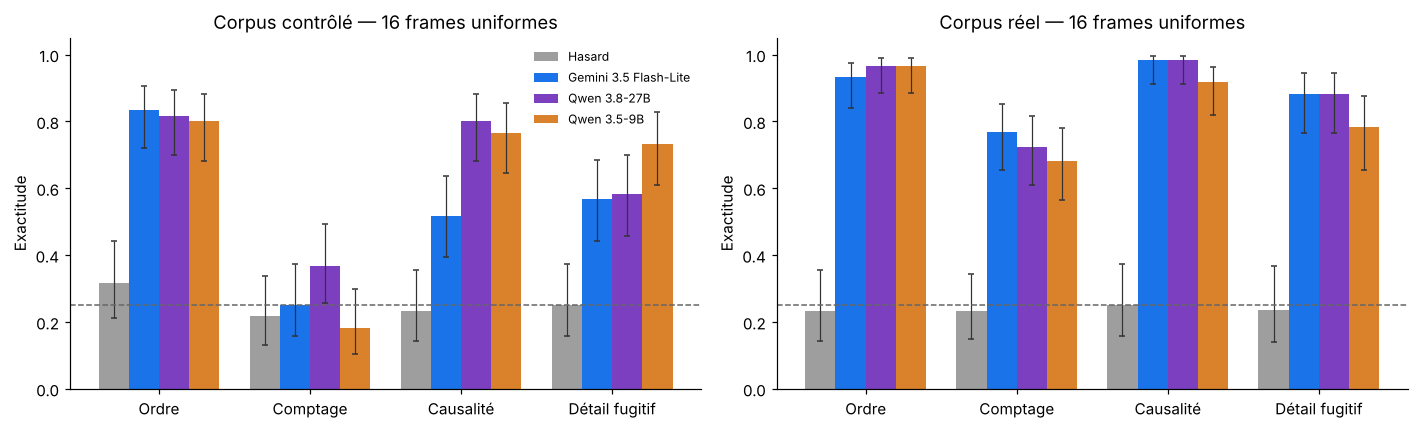

In [3]:
def acc_by_cat(d):
    out = []
    for (m, c), g in d.groupby(["model", "category"]):
        k, n = int(g["correct"].sum()), len(g)
        lo, hi = wilson(k, n)
        out.append(dict(model=m, category=c, acc=k / n, lo=lo, hi=hi, n=n))
    return pd.DataFrame(out)

corpora = list(df["corpus"].unique())
fig, axes = plt.subplots(1, len(corpora), figsize=(6.5 * len(corpora), 4), squeeze=False)
for ax, corp in zip(axes[0], corpora):
    a = acc_by_cat(df[(df.corpus == corp) & (df.strategy == "uniform")])
    models = [m for m in MODEL_ORDER if m in set(a.model)]
    w = 0.8 / len(models)
    for i, m in enumerate(models):
        s = a[a.model == m].set_index("category").reindex(CATS)
        x = np.arange(len(CATS)) + i * w
        ax.bar(x, s["acc"], w, color=COLORS[m], label=MODEL_LABEL[m])
        err = np.clip(np.nan_to_num(np.vstack([s["acc"] - s["lo"], s["hi"] - s["acc"]])), 0, None)
        ax.errorbar(x, s["acc"].fillna(0), yerr=err, fmt="none", ecolor="#333", lw=0.8, capsize=2)
    ax.axhline(0.25, ls="--", color="#666", lw=1)
    ax.set_xticks(np.arange(len(CATS)) + w * (len(models) - 1) / 2, [CAT_LABEL[c] for c in CATS])
    ax.set_ylim(0, 1.05); ax.set_ylabel("Exactitude"); ax.set_title(f"Corpus {corp} — 16 frames uniformes")
axes[0][0].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "accuracy_by_category.png", dpi=160, bbox_inches="tight"); plt.show()

## 3. Uniforme ou adaptatif ?

La sélection adaptative garde la moitié des frames réparties uniformément et choisit les autres aux pics de changement visuel.

strategy                                 adaptive  uniform  gain
corpus   model                category                          
contrôlé gemini-flash-lite-or causality      0.68     0.52  0.17
                              counting       0.35     0.25  0.10
                              fleeting       1.00     0.57  0.43
                              order          0.88     0.83  0.05
         qwen-27b-or          causality      0.80     0.80  0.00
                              counting       0.32     0.37 -0.05
                              fleeting       1.00     0.58  0.42
                              order          0.75     0.82 -0.07
         qwen-9b-or           causality      0.77     0.77  0.00
                              counting       0.30     0.18  0.12
                              fleeting       1.00     0.73  0.27
                              order          0.85     0.80  0.05
réel     gemini-flash-lite-or causality      1.00     0.98  0.02
                              counting       0.81     0.77  0.04
                              fleeting       0.98     0.88  0.10
                              order          0.90     0.93 -0.03
         qwen-27b-or          causality      0.98     0.98  0.00
                              counting       0.68     0.72 -0.04
                              fleeting       0.96     0.88  0.08
                              order          0.98     0.97  0.02
         qwen-9b-or           causality      0.98     0.92  0.07
                              counting       0.74     0.68  0.06
                              fleeting       0.94     0.78  0.16
                              order          0.97     0.97  0.00

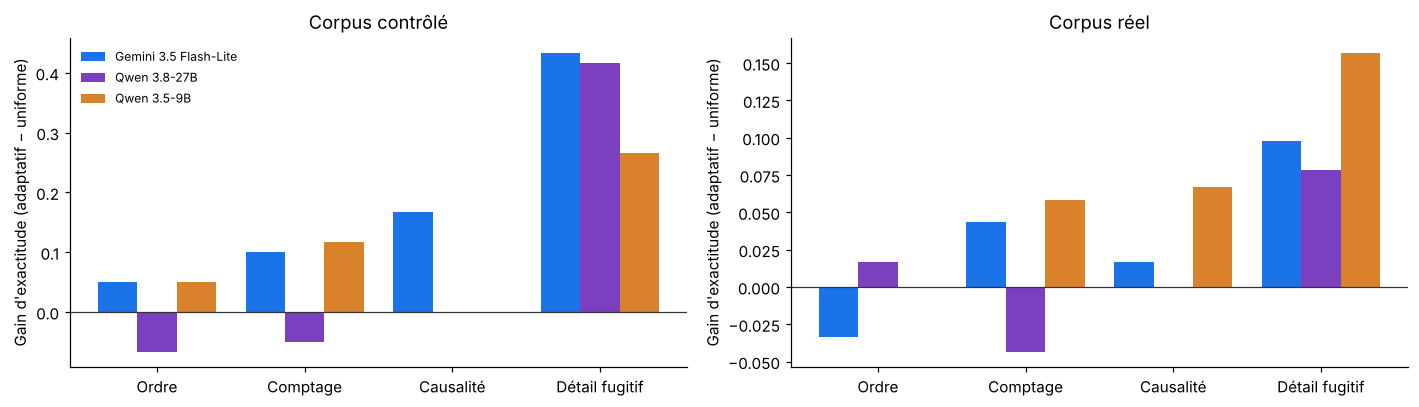

In [4]:
rows = []
for (corp, m, strat, c), g in df[df.model != "random"].groupby(["corpus", "model", "strategy", "category"]):
    rows.append(dict(corpus=corp, model=m, strategy=strat, category=c, acc=g["correct"].mean()))
t = pd.DataFrame(rows).pivot_table(index=["corpus", "model", "category"], columns="strategy", values="acc")
if {"uniform", "adaptive"} <= set(t.columns):
    t["gain"] = t["adaptive"] - t["uniform"]
display(t.round(2))

if {"uniform", "adaptive"} <= set(df.strategy):
    fig, axes = plt.subplots(1, len(corpora), figsize=(6.5 * len(corpora), 3.8), squeeze=False)
    for ax, corp in zip(axes[0], corpora):
        sub = t.loc[corp].reset_index()
        models = [m for m in MODEL_ORDER if m in set(sub.model)]
        w = 0.8 / len(models)
        for i, m in enumerate(models):
            s = sub[sub.model == m].set_index("category").reindex(CATS)
            ax.bar(np.arange(len(CATS)) + i * w, s["gain"], w, color=COLORS[m], label=MODEL_LABEL[m])
        ax.axhline(0, color="#333", lw=0.8)
        ax.set_xticks(np.arange(len(CATS)) + w * (len(models) - 1) / 2, [CAT_LABEL[c] for c in CATS])
        ax.set_ylabel("Gain d'exactitude (adaptatif − uniforme)"); ax.set_title(f"Corpus {corp}")
    axes[0][0].legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.savefig(FIG / "adaptive_gain.png", dpi=160, bbox_inches="tight"); plt.show()

## 4. Perception ou compréhension ?

Pour chaque question, on sait si au moins une frame envoyée tombe dans la fenêtre de preuve annotée (`evidence`).
Si le modèle se trompe alors que la preuve **n'était pas** dans les frames, c'est une erreur de perception imposée par
l'échantillonnage ; s'il se trompe alors qu'elle **était** visible, c'est une erreur de compréhension.

Couverture de la preuve (questions fugitives) :


strategy,adaptive,uniform
corpus,,
contrôlé,1.00,0.60
réel,0.82,0.71


Exactitude selon que la preuve était visible (seen=True) ou non :


mean  size
corpus   model                seen             
contrôlé gemini-flash-lite-or False  0.21    24
                              True   0.93    96
         qwen-27b-or          False  0.42    24
                              True   0.89    96
         qwen-9b-or           False  0.58    24
                              True   0.94    96
réel     gemini-flash-lite-or False  0.75    24
                              True   0.99    78
         qwen-27b-or          False  0.79    24
                              True   0.96    78
         qwen-9b-or           False  0.62    24
                              True   0.94    78

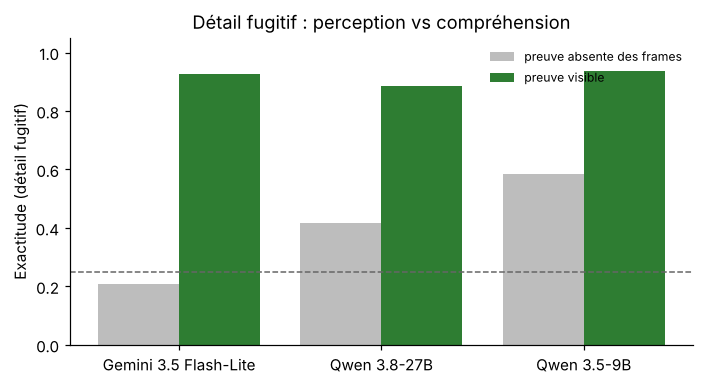

In [5]:
fl = df[(df.category == "fleeting") & (df.model != "random")]
cov = fl.groupby(["corpus", "strategy"])["seen"].mean().unstack().round(2)
print("Couverture de la preuve (questions fugitives) :"); display(cov)
pc = fl.groupby(["corpus", "model", "seen"])["correct"].agg(["mean", "size"]).round(2)
print("Exactitude selon que la preuve était visible (seen=True) ou non :"); display(pc)

d = fl[fl.corpus == "contrôlé"] if "contrôlé" in set(fl.corpus) else fl
g = d.groupby(["model", "seen"])["correct"].mean().unstack()
models = [m for m in MODEL_ORDER if m in g.index]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(models))
ax.bar(x - 0.2, g.reindex(models).get(False, pd.Series(np.nan, index=models)), 0.4, color="#bdbdbd", label="preuve absente des frames")
ax.bar(x + 0.2, g.reindex(models).get(True, pd.Series(np.nan, index=models)), 0.4, color="#2e7d32", label="preuve visible")
ax.axhline(0.25, ls="--", color="#666", lw=1)
ax.set_xticks(x, [MODEL_LABEL[m] for m in models]); ax.set_ylim(0, 1.05); ax.set_ylabel("Exactitude (détail fugitif)")
ax.set_title("Détail fugitif : perception vs compréhension"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "perception_vs_comprehension.png", dpi=160, bbox_inches="tight"); plt.show()

## 5. Stabilité aux reformulations

`consistency` : même lettre choisie pour les 3 formulations. `robust_acc` : les 3 formulations sont correctes.
L'écart entre exactitude moyenne et `robust_acc` mesure ce qu'on perd en exigeant la stabilité.

,corpus,model,acc,consistency,robust_acc
0,contrôlé,gemini-flash-lite-or,0.54,0.56,0.41
1,contrôlé,qwen-27b-or,0.64,0.51,0.46
2,contrôlé,qwen-9b-or,0.62,0.70,0.52
3,contrôlé,random,0.25,0.06,0.00
4,réel,gemini-flash-lite-or,0.89,0.94,0.86
5,réel,qwen-27b-or,0.88,0.85,0.81
6,réel,qwen-9b-or,0.83,0.80,0.75
7,réel,random,0.24,0.06,0.01


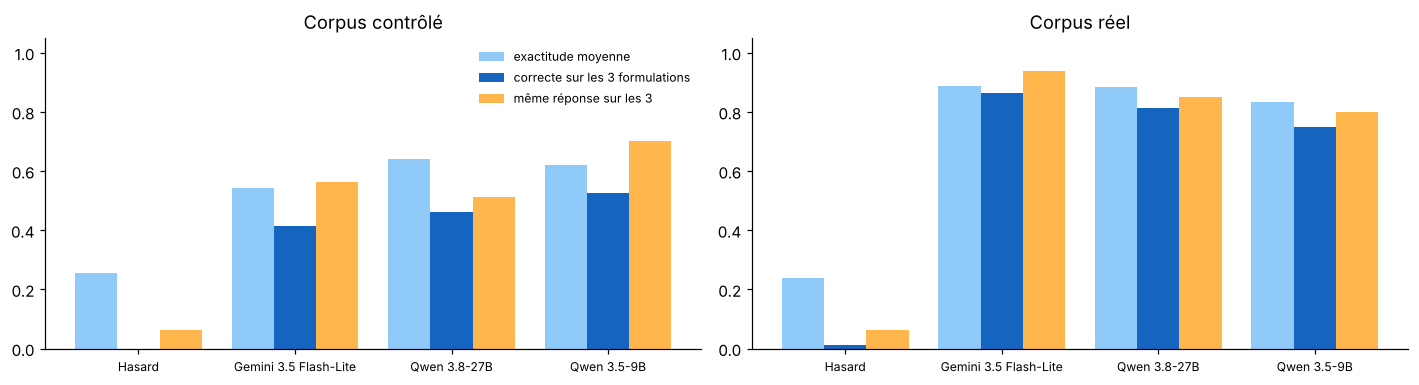

In [6]:
rows = []
for (corp, m, strat), g in df[df.strategy == "uniform"].groupby(["corpus", "model", "strategy"]):
    q = g.groupby("qid")
    rows.append(dict(corpus=corp, model=m, acc=g["correct"].mean(),
                     consistency=q["pred"].agg(lambda s: s.nunique(dropna=False) == 1).mean(),
                     robust_acc=q["correct"].all().mean()))
st = pd.DataFrame(rows); display(st.round(2))
fig, axes = plt.subplots(1, len(corpora), figsize=(6.5 * len(corpora), 3.6), squeeze=False)
for ax, corp in zip(axes[0], corpora):
    s = st[st.corpus == corp].set_index("model").reindex([m for m in MODEL_ORDER if m in set(st.model)])
    x = np.arange(len(s))
    for j, (col, lab, colr) in enumerate([("acc", "exactitude moyenne", "#90caf9"), ("robust_acc", "correcte sur les 3 formulations", "#1565c0"), ("consistency", "même réponse sur les 3", "#ffb74d")]):
        ax.bar(x + (j - 1) * 0.27, s[col], 0.27, label=lab, color=colr)
    ax.set_xticks(x, [MODEL_LABEL[m] for m in s.index], fontsize=8); ax.set_ylim(0, 1.05); ax.set_title(f"Corpus {corp}")
axes[0][0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "stability.png", dpi=160, bbox_inches="tight"); plt.show()

## 6. Biais de lettre

In [7]:
bias = (df[df.strategy == "uniform"].groupby(["corpus", "model"])["pred"].value_counts(normalize=True)
        .unstack(fill_value=0).round(2))
truth = df[(df.strategy == "uniform") & (df.model == "random")].groupby("corpus")["answer"].value_counts(normalize=True).unstack().round(2)
print("Répartition des lettres prédites :"); display(bias)
print("Répartition des bonnes réponses :"); display(truth)

Répartition des lettres prédites :


pred                              A     B     C     D
corpus   model                                       
contrôlé gemini-flash-lite-or  0.12  0.22  0.43  0.24
         qwen-27b-or           0.26  0.26  0.32  0.16
         qwen-9b-or            0.18  0.20  0.25  0.37
         random                0.30  0.23  0.24  0.22
réel     gemini-flash-lite-or  0.20  0.27  0.28  0.26
         qwen-27b-or           0.22  0.28  0.24  0.26
         qwen-9b-or            0.25  0.21  0.22  0.32
         random                0.30  0.23  0.24  0.22

Répartition des bonnes réponses :


answer,A,B,C,D
corpus,,,,
contrôlé,0.24,0.19,0.30,0.28
réel,0.25,0.25,0.25,0.25


## 7. Coût et latence

,corpus,model,n,cost_eur,eur_per_100q,lat_p50,lat_p95,acc
0,contrôlé,gemini-flash-lite-or,480,0.5816,0.1212,1.3125,1.9086,0.6354
1,contrôlé,qwen-27b-or,480,0.0767,0.0160,1.0110,1.9591,0.6792
2,contrôlé,qwen-9b-or,480,0.1157,0.0241,1.0390,1.9127,0.6750
3,réel,gemini-flash-lite-or,480,0.5734,0.1195,1.3805,1.9401,0.9021
4,réel,qwen-27b-or,480,0.0655,0.0136,1.2430,2.5472,0.8875
5,réel,qwen-9b-or,480,0.1177,0.0245,1.2875,2.3071,0.8667


Coût total de la campagne : 1.531 €


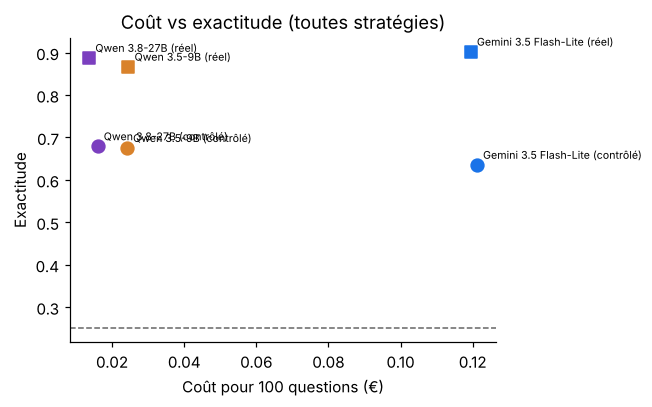

In [8]:
rows = []
for (corp, m), g in df[df.model != "random"].groupby(["corpus", "model"]):
    rows.append(dict(corpus=corp, model=m, n=len(g), cost_eur=g["cost_eur"].sum(), eur_per_100q=100 * g["cost_eur"].mean(),
                     lat_p50=g["latency_s"].median(), lat_p95=g["latency_s"].quantile(0.95), acc=g["correct"].mean()))
cl = pd.DataFrame(rows); display(cl.round(4))
print(f"Coût total de la campagne : {df['cost_eur'].sum():.3f} €")
fig, ax = plt.subplots(figsize=(6, 3.8))
for _, r in cl.iterrows():
    ax.scatter(r["eur_per_100q"], r["acc"], s=70, color=COLORS[r["model"]], marker="o" if r["corpus"] == "contrôlé" else "s")
    ax.annotate(f"{MODEL_LABEL[r['model']]} ({r['corpus']})", (r["eur_per_100q"], r["acc"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.axhline(0.25, ls="--", color="#666", lw=1)
ax.set_xlabel("Coût pour 100 questions (€)"); ax.set_ylabel("Exactitude"); ax.set_title("Coût vs exactitude (toutes stratégies)")
plt.tight_layout(); plt.savefig(FIG / "cost_vs_accuracy.png", dpi=160, bbox_inches="tight"); plt.show()

## 8. Baseline aveugle : les questions se devinent-elles sans la vidéo ?

Les mêmes questions (formulation d'origine) sont posées **sans aucune image**. Une exactitude nettement supérieure
au hasard signifie que la question se devine par le bon sens ou par la forme des options : elle ne mesure alors pas
la compréhension de la vidéo.

category                       causality  counting  fleeting  order  global_
corpus   model                                                              
contrôlé gemini-flash-lite-or       0.10      0.30      0.50   0.25     0.29
         qwen-27b-or                0.30      0.25      0.20   0.45     0.30
réel     gemini-flash-lite-or       0.55      0.22      0.53   0.65     0.48
         qwen-27b-or                0.80      0.30      0.82   0.55     0.60

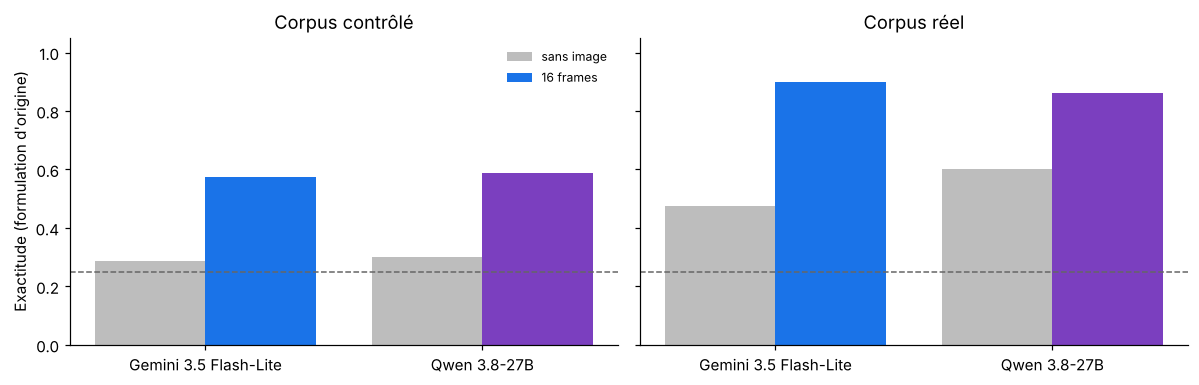

Corpus réel : 28 questions sur 80 devinées sans image par les deux modèles.


devinable                      False  True 
model                strategy              
gemini-flash-lite-or adaptive   0.87   1.00
                     uniform    0.83   1.00
qwen-27b-or          adaptive   0.84   0.99
                     uniform    0.83   0.99
qwen-9b-or           adaptive   0.86   0.98
                     uniform    0.78   0.93
random               adaptive   0.22   0.26
                     uniform    0.22   0.26

In [9]:
blind = []
for name, corpus in [("blind_synthetic.jsonl", "contrôlé"), ("blind_real.jsonl", "réel")]:
    p = ROOT / "results" / name
    if p.exists():
        b = pd.read_json(p, lines=True); b["corpus"] = corpus; blind.append(b)
blind = pd.concat(blind, ignore_index=True)
display(blind.pivot_table(index=["corpus", "model"], columns="category", values="correct", aggfunc="mean")
        .assign(global_=blind.groupby(["corpus", "model"]).correct.mean()).round(2))

with_img = df[(df.strategy == "uniform") & (df.variant == 0) & (df.model.isin(blind.model.unique()))]
comp = pd.DataFrame({"sans image": blind.groupby(["corpus", "model"]).correct.mean(),
                     "16 frames": with_img.groupby(["corpus", "model"]).correct.mean()}).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, corp in zip(axes, ["contrôlé", "réel"]):
    c = comp[comp.corpus == corp].set_index("model")
    x = np.arange(len(c))
    ax.bar(x - 0.2, c["sans image"], 0.4, color="#bdbdbd", label="sans image")
    ax.bar(x + 0.2, c["16 frames"], 0.4, color=[COLORS[m] for m in c.index], label="16 frames")
    ax.axhline(0.25, ls="--", color="#666", lw=1)
    ax.set_xticks(x, [MODEL_LABEL[m] for m in c.index]); ax.set_ylim(0, 1.05); ax.set_title(f"Corpus {corp}")
axes[0].set_ylabel("Exactitude (formulation d'origine)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "blind_baseline.png", dpi=160, bbox_inches="tight"); plt.show()

br = blind[blind.corpus == "réel"]
guessable = set(br.groupby("qid").correct.all().pipe(lambda s: s[s].index))
print(f"Corpus réel : {len(guessable)} questions sur 80 devinées sans image par les deux modèles.")
r = df[df.corpus == "réel"].assign(devinable=lambda d: d.qid.isin(guessable))
display(r.pivot_table(index=["model", "strategy"], columns="devinable", values="correct", aggfunc="mean").round(2))

## 9. Le comptage est-il un problème de perception ?

Sur le corpus contrôlé, la lampe s'allume 0,35 à 0,6 s ; 16 frames sur 10 s sont espacées de 0,625 s, donc une
partie des clignotements tombe entre deux frames. On relance les seules questions de comptage avec **32 frames**.

cfg,adaptive 16,uniform 16,uniform 32
model,,,
gemini-flash-lite-or,0.35,0.25,0.48
qwen-27b-or,0.32,0.37,0.47
qwen-9b-or,0.30,0.18,0.35


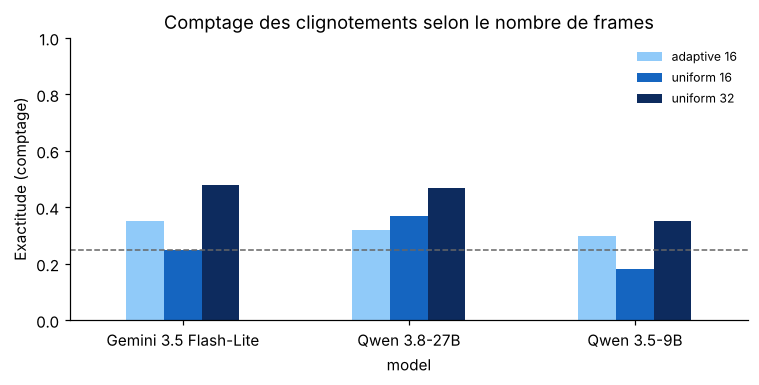

Écart moyen (prédit − vrai) :


cfg,adaptive 16,uniform 16,uniform 32
model,,,
gemini-flash-lite-or,-0.36,-0.54,-0.09
qwen-27b-or,-0.20,-0.33,0.15
qwen-9b-or,-0.72,-0.80,-0.43


In [10]:
p32 = ROOT / "results" / "synthetic_counting_32.jsonl"
if p32.exists():
    c32 = pd.read_json(p32, lines=True)
    c16 = df[(df.corpus == "contrôlé") & (df.category == "counting") & (df.model != "random")]
    t = pd.concat([c16.assign(cfg=c16.strategy + " 16"), c32.assign(cfg="uniform 32")])
    tab = t.pivot_table(index="model", columns="cfg", values="correct", aggfunc="mean").round(2)
    display(tab)
    ax = tab.reindex([m for m in MODEL_ORDER if m in tab.index]).rename(index=MODEL_LABEL).plot.bar(
        figsize=(7, 3.6), color=["#90caf9", "#1565c0", "#0d2b5e"], rot=0)
    ax.axhline(0.25, ls="--", color="#666", lw=1); ax.set_ylabel("Exactitude (comptage)"); ax.set_ylim(0, 1)
    ax.set_title("Comptage des clignotements selon le nombre de frames"); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.savefig(FIG / "counting_frames.png", dpi=160, bbox_inches="tight"); plt.show()
    # erreurs : sous-comptage ou sur-comptage ?
    import json as _j
    qs = {(_q := _j.loads(l))["qid"]: _q for l in open(ROOT / "data/synthetic/questions.jsonl")}
    def signed(row):
        q = qs[row.qid]
        if row.pred is None or pd.isna(row.pred): return np.nan
        return int(q["options"]["ABCD".index(row.pred)]) - int(q["options"]["ABCD".index(q["answer"])])
    t["ecart"] = t.apply(signed, axis=1)
    print("Écart moyen (prédit − vrai) :"); display(t.groupby(["model", "cfg"]).ecart.mean().unstack().round(2))

## 10. Conclusions

*Rédigées à partir des résultats de la campagne du 27/11/2026 — à reformuler par le groupe.*

1. **Sélection adaptative.** C'est l'extension la plus rentable : à coût égal (16 frames), elle porte l'exactitude
   « détail fugitif » du corpus contrôlé de 0,57–0,73 à 1,00, parce que la preuve passe de 60 % à 100 % de couverture.
   Les erreurs sur les détails brefs sont donc surtout des erreurs de **perception** dues à l'échantillonnage.
2. **Comptage.** C'est la catégorie la plus faible (0,18–0,37 à 16 frames, proche du hasard). Doubler les frames
   aide (0,35–0,48) et réduit le sous-comptage, sans résoudre le problème : les modèles peinent à suivre un même
   objet d'une frame à l'autre.
3. **Validité du corpus réel.** La baseline sans image montre que 28 questions réelles sur 80 se devinent : les scores
   réels (≈ 0,9) surestiment la compréhension. Le corpus contrôlé, au niveau du hasard sans image, est la mesure la
   plus fiable. Priorité : réécrire les questions réelles devinables avec des distracteurs plausibles.
4. **Stabilité.** Une reformulation change la réponse dans 30 à 50 % des questions du corpus contrôlé : une seule
   formulation par question donnerait une image trop optimiste et bruitée. `robust_acc` est la métrique à retenir.
5. **Coût.** 1,74 € pour l'ensemble des campagnes. Qwen 3.8-27B obtient des résultats comparables à Gemini 3.5
   Flash-Lite pour un coût huit fois plus faible ; le petit Qwen 3.5-9B reste proche, ce qui rend crédible un
   déploiement local.
